# D-He3 model

In [1]:
import openmc
import numpy as np
import math
import matplotlib.pyplot as plt
from fusion_fuel_concepts_explorer.sources import SteadyStateSource

In [2]:
avg_density_Dhe3 = 1.3e20
avg_temperature_Dhe3 = 70.0
density_peaking_DHe3 = 2.5
temperature_peaking_DHe3 = 2
density_profile_DHe3 = lambda rho: avg_density_Dhe3 * density_peaking_DHe3 * ((1.0 - rho**2.0) ** (density_peaking_DHe3 - 1.0))
temperature_profile_DHe3 = lambda rho: avg_temperature_Dhe3 * temperature_peaking_DHe3 * ((1.0 - rho**2.0) ** (temperature_peaking_DHe3 - 1.0))

DHe3_source = SteadyStateSource(
    source_type="DHe3",
    volume_m3=150.0,
    n_i=density_profile_DHe3,
    T_i=temperature_profile_DHe3,
    tau_p=2.5,
)

number_of_neutrons_per_second = DHe3_source.reaction_rates_s['DT'] + DHe3_source.reaction_rates_s['DDn'] + DHe3_source.reaction_rates_s['TT'] + DHe3_source.reaction_rates_s['THe3_np']
print("Number of neutrons per second", number_of_neutrons_per_second, '\n')
eV_to_Jouls = 1.60218e-19
joules_to_mega_joules = 1e-6

# Volume (to be calculated)
tf_coil_magnet_volume = 337409.34 # * 18 if reflective BC.. TBV
tf_coil_insulation_volume = 2990501.95 # * 18
tf_coil_case_volume = 4881775.41 # * 18
ybco_volume = 0.01 * tf_coil_magnet_volume # about 1% of the total (literature), according to the definition in OpenMC it would be 0.72%

Number of neutrons per second 1.589518216296959e+19 



## TBR

In [3]:
sp = openmc.StatePoint("statepoint.100.h5")

tbr = sp.get_tally(name='TBR_total')
df_tbr = tbr.get_pandas_dataframe()
tbr_mean = df_tbr["mean"].sum()
tbr_std = (df_tbr["std. dev."]**2).sum()**0.5
print(f"The reactor has a TBR of {tbr_mean:.4f} ± {tbr_std:.4f}")

The reactor has a TBR of 0.0140 ± 0.0030


In [4]:
tbr_channel = sp.get_tally(name='TBR_channel')
df_tbr_c = tbr_channel.get_pandas_dataframe()
tbr_c_mean = df_tbr_c["mean"].sum()
tbr_c_std = (df_tbr_c["std. dev."]**2).sum()**0.5
print(f"The Channel has a TBR of {tbr_c_mean:.4f} ± {tbr_c_std:.4f}")

tbr_breeder = sp.get_tally(name='TBR_breeder')
df_tbr_breeder = tbr_breeder.get_pandas_dataframe()
tbr_breeder_mean = df_tbr_breeder["mean"].sum()
tbr_breeder_std = (df_tbr_breeder["std. dev."]**2).sum()**0.5
print(f"The Breeder has a TBR of {tbr_breeder_mean:.4f} ± {tbr_breeder_std:.4f}")

print(f"Sum of contributions = {tbr_c_mean+tbr_breeder_mean:.4f}")

The Channel has a TBR of 0.0000 ± 0.0000
The Breeder has a TBR of 0.0000 ± 0.0000
Sum of contributions = 0.0000


## Power deposition

In [5]:
def compute_power_and_density(name, volume):
    """
    Compute deposited power (MW) and power density (MW/m^3)
    from an OpenMC tally, including statistical uncertainty (1σ).

    Parameters
    ----------
    name : str
        Name of the tally to extract (e.g., "heating_full").
    volume : float
        Volume of the region in m^3.

    Returns
    -------
    h_MW : float
        Total deposited power in MW.
    h_std_MW : float
        Standard deviation of deposited power (MW).
    pd_MW_m3 : float
        Power density in MW/m^3.
    pd_std_MW_m3 : float
        Standard deviation of power density (MW/m^3).
    """

    # Extract the tally
    tally = sp.get_tally(name=name)

    # Mean and standard deviation arrays
    mean_vals = tally.mean.flatten()
    std_vals  = tally.std_dev.flatten()

    # Sum of means
    total_mean = mean_vals.sum()

    # Propagated std dev (quadrature)
    total_std = (std_vals**2).sum()**0.5

    # Convert to MW
    h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
    h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

    # Power density
    pd_MW_m3 = h_MW / volume
    pd_std_MW_m3 = h_std_MW / volume

    # Relative error
    rel_err = h_std_MW / h_MW if h_MW != 0 else 0.0

    # Print results
    print(f"Results for tally '{name}':")
    print(f"Power deposited: {h_MW:.3f} ± {h_std_MW:.3f} MW "
          f"({100*rel_err:.2f} %)")
    print(f"Power density:   {pd_MW_m3:.3f} ± {pd_std_MW_m3:.3f} MW/m^3\n")

    return h_MW, h_std_MW, pd_MW_m3, pd_std_MW_m3

In [6]:
h_tf_coil_magnet, h_std_tf_coil_magnet, pd_tf_coil_magnet, pd_std_tf_coil_magnet = compute_power_and_density("q_vol_tf_coil_magnet", tf_coil_magnet_volume)
h_tf_coil_insulation, h_std_tf_coil_insulation, pd_tf_coil_insulation, pd_std_tf_coil_insulation = compute_power_and_density("q_vol_tf_coil_insulation", tf_coil_insulation_volume)
h_tf_coil_case, h_std_tf_coil_case, pd_tf_coil_case, pd_std_tf_coil_case = compute_power_and_density("q_vol_tf_coil_case", tf_coil_case_volume)

Results for tally 'q_vol_tf_coil_magnet':
Power deposited: 0.001 ± 0.001 MW (92.51 %)
Power density:   0.000 ± 0.000 MW/m^3

Results for tally 'q_vol_tf_coil_insulation':
Power deposited: 0.010 ± 0.010 MW (97.72 %)
Power density:   0.000 ± 0.000 MW/m^3

Results for tally 'q_vol_tf_coil_case':
Power deposited: 0.048 ± 0.010 MW (20.20 %)
Power density:   0.000 ± 0.000 MW/m^3



In [7]:
qvol_tot = sp.get_tally(name='heating_full')

# Sum over the mean values
total_mean = qvol_tot.mean.sum()
std_vals  = qvol_tot.std_dev.flatten()
total_std = (std_vals**2).sum()**0.5

# Compute deposited power (in MW)
h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# Print results
print(f"Power deposited on the entire geometry: {h_MW:.3f} ± {h_std_MW:.3f}  MW")

Power deposited on the entire geometry: 26.154 ± 1.084  MW


In [8]:
# q_vol_tf_coil_magnet = sp.get_tally(name='q_vol_tf_coil_magnet')

# total_mean = q_vol_tf_coil_magnet.mean.sum()
# std_vals  = q_vol_tf_coil_magnet.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil magnet: {h_MW:.3f} ± {h_std_MW:.3f}  MW")
# q_vol_tf_coil_insulation = sp.get_tally(name='q_vol_tf_coil_insulation')

# total_mean = q_vol_tf_coil_insulation.mean.sum()
# std_vals  = q_vol_tf_coil_insulation.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil insulation: {h_MW:.3f} ± {h_std_MW:.3f}  MW")
# q_vol_tf_coil_case = sp.get_tally(name='q_vol_tf_coil_case')

# total_mean = q_vol_tf_coil_case.mean.sum()
# std_vals  = q_vol_tf_coil_case.std_dev.flatten()
# total_std = (std_vals**2).sum()**0.5

# h_MW = eV_to_Jouls * number_of_neutrons_per_second * total_mean / 1e6
# h_std_MW = eV_to_Jouls * number_of_neutrons_per_second * total_std / 1e6

# print(f"Power deposited on TF coil insulation: {h_MW:.3f} ± {h_std_MW:.3f}  MW")

## Neutron flux

In [9]:
def plot_flux_spectrum(sp, name, volume, number_of_neutrons_per_second):

    import numpy as np
    import matplotlib.pyplot as plt
    import openmc

    energy_bins = openmc.mgxs.GROUP_STRUCTURES['TRIPOLI-315']
    energy_filter = openmc.EnergyFilter(energy_bins)

    tally = sp.get_tally(name=name)

    # Convert tally results to numpy arrays
    mean = np.asarray(tally.mean)
    std  = np.asarray(tally.std_dev)

    # Determine number of energy groups and spatial bins
    n_energy = len(energy_bins) - 1
    n_cells = int(len(mean) / n_energy)

    # Reshape tally results: (cells, energy groups)
    mean = mean.reshape((n_cells, n_energy))
    std  = std.reshape((n_cells, n_energy))

    # Sum contributions from all cells
    flux = mean.sum(axis=0)

    # Propagate statistical uncertainty
    flux_std = np.sqrt((std**2).sum(axis=0))

    # Normalize flux by region volume and source strength
    flux_region = (flux / volume) * number_of_neutrons_per_second
    flux_err = (flux_std / volume) * number_of_neutrons_per_second

    # Energy axis in MeV
    E = energy_filter.values[:-1] / 1e6

    # Plot neutron flux spectrum
    plt.figure(figsize=(8,6))

    plt.step(E, flux_region, where='post', label='Neutron Flux')

    plt.fill_between(
        E,
        flux_region - 3*flux_err,
        flux_region + 3*flux_err,
        step='post',
        alpha=0.25,
        label='Flux ±3σ'
    )

    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Energy [MeV]')
    plt.ylabel('Flux [n/cm²/s]')
    plt.xlim(2e-7, 30)
    plt.grid(alpha=0.2, which='both')
    plt.legend()
    plt.title(name)
    plt.show()

    # Compute flux integrated over different energy ranges
    flux_total = flux_region.sum()
    flux_total_std = np.sqrt((flux_err**2).sum())

    flux_above_7 = flux_region[E > 7].sum()
    flux_above_7_std = np.sqrt((flux_err[E > 7]**2).sum())

    flux_1_to_7 = flux_region[(E >= 1) & (E <= 7)].sum()
    flux_1_to_7_std = np.sqrt((flux_err[(E >= 1) & (E <= 7)]**2).sum())

    flux_below_1 = flux_region[E < 1].sum()
    flux_below_1_std = np.sqrt((flux_err[E < 1]**2).sum())

    # Print flux values with uncertainty
    print(f"Total flux        = {flux_total:.3e} ± {flux_total_std:.3e} n/cm²/s")
    print(f"Flux > 7 MeV      = {flux_above_7:.3e} ± {flux_above_7_std:.3e} n/cm²/s")
    print(f"Flux 1–7 MeV      = {flux_1_to_7:.3e} ± {flux_1_to_7_std:.3e} n/cm²/s")
    print(f"Flux < 1 MeV      = {flux_below_1:.3e} ± {flux_below_1_std:.3e} n/cm²/s")

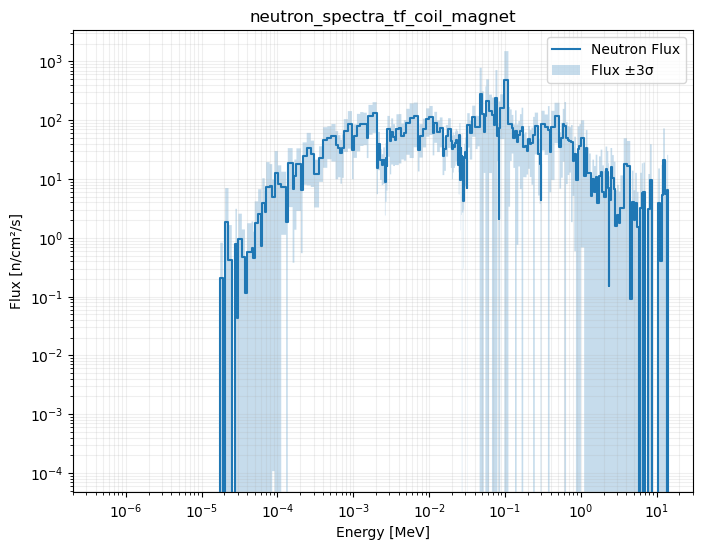

Total flux        = 8.841e+03 ± 4.727e+02 n/cm²/s
Flux > 7 MeV      = 5.604e+01 ± 2.218e+01 n/cm²/s
Flux 1–7 MeV      = 3.354e+02 ± 3.313e+01 n/cm²/s
Flux < 1 MeV      = 8.449e+03 ± 4.710e+02 n/cm²/s


In [10]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_magnet',
    volume=tf_coil_magnet_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

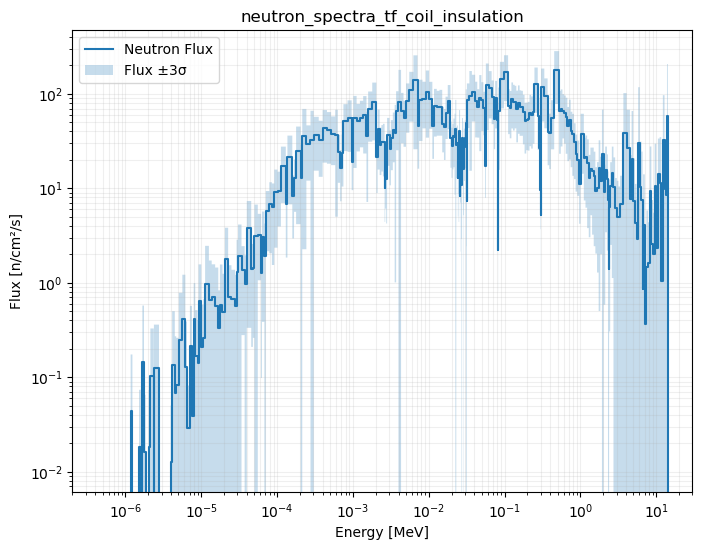

Total flux        = 8.342e+03 ± 1.671e+02 n/cm²/s
Flux > 7 MeV      = 1.659e+02 ± 5.673e+01 n/cm²/s
Flux 1–7 MeV      = 5.009e+02 ± 4.927e+01 n/cm²/s
Flux < 1 MeV      = 7.675e+03 ± 1.493e+02 n/cm²/s


In [11]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_insulation',
    volume=tf_coil_insulation_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

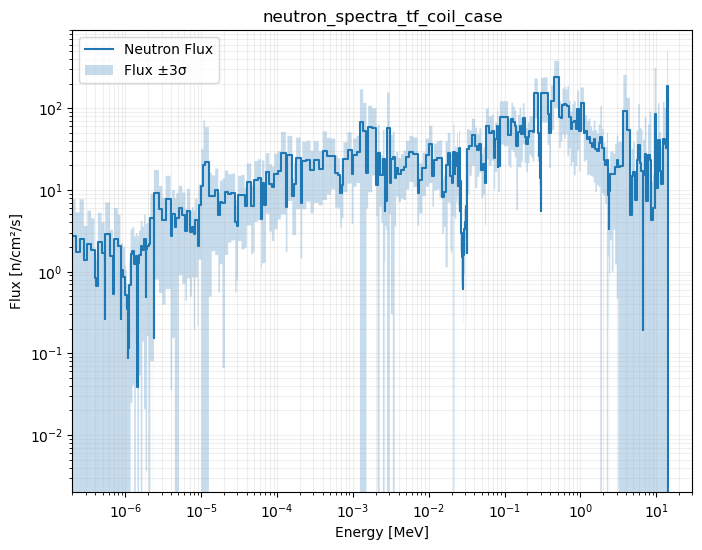

Total flux        = 7.945e+03 ± 2.694e+02 n/cm²/s
Flux > 7 MeV      = 5.586e+02 ± 1.405e+02 n/cm²/s
Flux 1–7 MeV      = 1.118e+03 ± 8.336e+01 n/cm²/s
Flux < 1 MeV      = 6.268e+03 ± 2.142e+02 n/cm²/s


In [12]:
plot_flux_spectrum(
    sp,
    name='neutron_spectra_tf_coil_case',
    volume=tf_coil_case_volume*1e6,
    number_of_neutrons_per_second=number_of_neutrons_per_second
)

## DPA

In [13]:
dpa_ybco_tally = sp.get_tally(name="dpa_ybco")
df_dpa_ybco = dpa_ybco_tally.get_pandas_dataframe()


damage_energy_in_eV = df_dpa_ybco['mean'].sum()
print('Damage energy deposited in YBCO per source neutron = ', damage_energy_in_eV, 'eV/source')

print('Two times the threshold energy of 40 eV is needed to displace an atom')
displacement_per_source_neutron = damage_energy_in_eV / (2 * 40)
print('Displacements per source neutron = ', displacement_per_source_neutron, 'eV/source')

print('Assuming 80% remanins after 20% recombine to original lattice locations')
displacements_per_source_neutron_with_recombination = displacement_per_source_neutron * 0.8
print('Displacements per source neutron after recombination = ', displacements_per_source_neutron_with_recombination, '\n')

number_of_neutrons_per_year = number_of_neutrons_per_second * 60 * 60 * 24 * 365.25
print('Number of neutrons per full power year ', number_of_neutrons_per_year)

displacements_for_all_atoms = number_of_neutrons_per_year * displacements_per_source_neutron_with_recombination
print('Displacements for all atoms in the volume ', displacements_for_all_atoms, '\n')

print('Now the number of atoms in the volume must be found to find displacements per atom (DPA)')

ybco_atomic_mass_in_g = 33.9 * 1.66054e-24

density_of_ybco_in_g_per_cm3 = 6.3

number_of_ybco_atoms = ybco_volume * density_of_ybco_in_g_per_cm3 / (ybco_atomic_mass_in_g)

print('Number of atoms on YBCO tape', number_of_ybco_atoms, '\n')

DPA = displacements_for_all_atoms / number_of_ybco_atoms
print('DPA =', DPA)

Damage energy deposited in YBCO per source neutron =  0.049311239855765104 eV/source
Two times the threshold energy of 40 eV is needed to displace an atom
Displacements per source neutron =  0.0006163904981970638 eV/source
Assuming 80% remanins after 20% recombine to original lattice locations
Displacements per source neutron after recombination =  0.000493112398557651 

Number of neutrons per full power year  5.016138006261291e+26
Displacements for all atoms in the volume  2.4735198437636987e+23 

Now the number of atoms in the volume must be found to find displacements per atom (DPA)
Number of atoms on YBCO tape 3.776144544513775e+26 

DPA = 0.000655038443207209


## Mesh

In [14]:
mesh = openmc.RegularMesh()
mesh.dimension = [128, 48, 200]
mesh.lower_left = [40, -120, -500]
mesh.upper_right = [680, 120, 500]

In [15]:
gas_production_tally = sp.get_tally(name='gas_pruduction_mesh')
tbr_tally = gas_production_tally.get_slice(scores=['(n,Xt)'])

# converts the tally result into a VTK file
mesh.write_data_to_vtk(
    filename="tbr_tally_on_reg_mesh.vtk",
    datasets={"n_Xt": tbr_tally.mean}
)

<StructuredGrid(0x58de4cc7ab60) at 0x7a8d72cd27a0>

In [16]:
heating_tally = sp.get_tally(name='heating_mesh')

# Extract neutron-only heating
neutron_heating = heating_tally.get_slice(
    filters=[openmc.ParticleFilter],
    filter_bins=[('neutron',)]
)

# Compute total heating by summing over all particle bins
particle_filter = heating_tally.find_filter(openmc.ParticleFilter)
n_particles = len(particle_filter.bins)
n_mesh = np.prod(mesh.dimension)

data = heating_tally.mean.reshape((n_particles, n_mesh))
total_heating = data.sum(axis=0)

# Export both datasets to VTK
mesh.write_data_to_vtk(
    filename="heating_mesh.vtk",
    datasets={
        "heating_neutron": neutron_heating.mean,
        "heating_total": total_heating
    }
)

<StructuredGrid(0x58de4cc7c850) at 0x7a8d72cd30a0>

# Radial plot
## Inner Plot

In [17]:
heating_n_mesh_tally = sp.get_tally(name="i_r_q_vol")

data_n = heating_n_mesh_tally.mean.flatten()

scaling_factor = number_of_neutrons_per_second * eV_to_Jouls * joules_to_mega_joules / 18
mesh = heating_n_mesh_tally.find_filter(openmc.MeshFilter).mesh

volume_normalization = mesh.volumes[0][0][0] * 1e-6  # in m3

data_n = data_n * scaling_factor
data = data_n / volume_normalization
data = data[::-1] # reverse data to match x direction

lower = 0.0
upper = 69.5
nx = 695*2

x = np.linspace(lower, upper, nx)

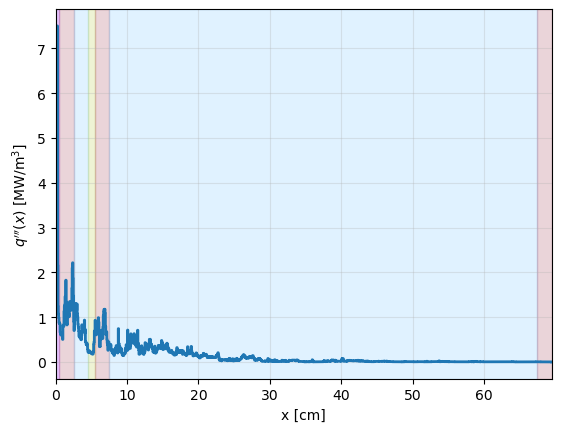

In [18]:
idx0 = np.argmax(data > 0)
x_plot = x[idx0:] - x[idx0]  
data_plot = data[idx0:]

fig, ax = plt.subplots()

ax.set_xlabel("x [cm]")


ax.set_ylabel(r"$q'''(x)$ [MW/m$^3$]")

bands = [
    (0, 0.5, "FW"),
    (0.5, 2.5, "VV"),
    (2.5, 4.5, "Channel"),
    (4.5, 5.5, "Neutron Multiplier"),
    (5.5, 7.5, "VV"),
    (7.5, 67.5, "Blanket"),
    (67.5, 69.5, "Shield")
]

colors = ["#8c00ff", "#992941", "#66c2ff", "#adc528", "#992941",  "#66c2ff", "#992941"]

for (x1, x2, label), color in zip(bands, colors):
    ax.axvspan(x1, x2, alpha=0.20, color=color)
    
# Plot
ax.step(x_plot, data_plot, where='post', linewidth=2)
ax.set_xlim(0, 69.5)

ax.grid(alpha=0.3, which="both")
plt.show()

## Outer plot

In [19]:
heating_n_mesh_tally = sp.get_tally(name="o_r_q_vol")

data_n = heating_n_mesh_tally.mean.flatten()

scaling_factor = number_of_neutrons_per_second * eV_to_Jouls * joules_to_mega_joules / 18
mesh = heating_n_mesh_tally.find_filter(openmc.MeshFilter).mesh

volume_normalization = mesh.volumes[0][0][0] * 1e-6  # in m3

data_n = data_n * scaling_factor
data = data_n / volume_normalization

lower = 0.0
upper = 69.5
nx = 695*2

x = np.linspace(lower, upper, nx)

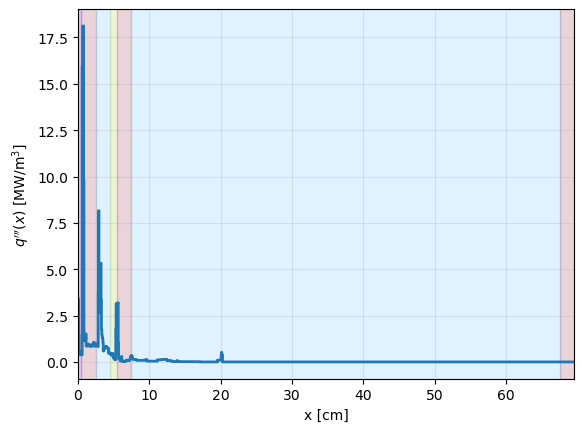

In [20]:
idx0 = np.argmax(data > 0)
x_plot = x[idx0:] - x[idx0]  
data_plot = data[idx0:]

fig, ax = plt.subplots()

ax.set_xlabel("x [cm]")


ax.set_ylabel(r"$q'''(x)$ [MW/m$^3$]")

bands = [
    (0, 0.5, "FW"),
    (0.5, 2.5, "VV"),
    (2.5, 4.5, "Channel"),
    (4.5, 5.5, "Neutron Multiplier"),
    (5.5, 7.5, "VV"),
    (7.5, 67.5, "Blanket"),
    (67.5, 69.5, "Shield")
]

colors = ["#8c00ff", "#992941", "#66c2ff", "#adc528", "#992941",  "#66c2ff", "#992941"]

for (x1, x2, label), color in zip(bands, colors):
    ax.axvspan(x1, x2, alpha=0.20, color=color)
    
# Plot
ax.step(x_plot, data_plot, where='post', linewidth=2)
ax.set_xlim(0, 69.5)

ax.grid(alpha=0.3, which="both")
plt.show()